In [83]:
'''
a demonstration of a fixed point decay trajectory
the aim is to show that initially, fixed point decays at a rate of  (1+s^2/y^2)*w_d and only then gradually slows to w_d
where w_d is the weight decay rate.
'''

'\na demonstration of a fixed point decay trajectory\nthe aim is to show that initially, fixed point decays at a rate of  (1+s^2/y^2)*w_d and only then gradually slows to w_d\nwhere w_d is the weight decay rate.\n'

In [84]:
# load a matrix from a space-separated file and show it as an image
import sys
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/')
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import os
from stat_utils import bic_gaussian_from_rmse
from model_utils import force_model_params, migrate_output_scale_to_input_scale_state_dict
from part2fig_utils import eval_paradigm_with_inoutmaps, find_fixed_points, eval_single_wrap, eval_single_paradigm


def compute_k_params(model_state_dict, 
                     exclude_by_startwith=['_'], 
                     exclude_by_name=['sigma_x'], 
                     count_for_one={'sigma_b', 'direct_injection_scale','output_scale','u_feedback_scale', 
                                    'x_slow_alpha', 'x_fast_gain', 'x_fast_alpha'}):
    k_params = 0
    for key in model_state_dict:
        if any([key.startswith(excl) for excl in exclude_by_startwith]):
            continue
        if key in exclude_by_name:
            continue
        param_tensor = model_state_dict[key]
        this_param_size = param_tensor.shape[-1] if key not in count_for_one else 1
        print(f'param: {key}, size: {this_param_size}')
        k_params += this_param_size
    return k_params

def read_rmse_and_bic_from_path(bic_path,seeds):
    model_state_dict = torch.load(os.path.join(bic_path, 'model_state_dict.pt'), map_location='cpu')
    k_params = compute_k_params(model_state_dict)
    print(f'detected k_params: {k_params}')
    a_exp = np.loadtxt(os.path.join(bic_path, 'a_exp.txt'))
    a_pred = np.loadtxt(os.path.join(bic_path, 'a_pred.txt'))

    subjs = a_exp.shape[1] // seeds
    print(f'detected subjs: {subjs}')

    se = np.nansum((a_exp - a_pred) ** 2,axis=0).reshape([subjs, seeds])
    bad_seeds = np.any(np.isnan(a_pred), axis=0).reshape([subjs, seeds])

    se = se + bad_seeds * 1e100

    # print(f'se: {se}')
    se_per_seed = np.sum(se, axis=0)
    print(f'se_per_seed: {se_per_seed}')
    best_seed = np.argmin(se_per_seed)
    seeds_ranked = np.argsort(se_per_seed)
    best_seed_idx = [best_seed + i*seeds for i in range(subjs)]
    print(f'best_seed_idx: {best_seed_idx}')

    rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0))
    n_samples = np.sum(~np.isnan(a_exp),axis=0).reshape([subjs, seeds])
    assert np.all(n_samples == n_samples[:, [0]])
    n_samples = n_samples[:, 0]

    # best_seed_idx = np.nanargmin(rmse, axis=1)
    best_rmse = rmse[best_seed_idx]
    best_bics = [bic_gaussian_from_rmse(this_rmse, n=this_n, k=k_params) for this_rmse, this_n in zip(best_rmse, n_samples)]
    return {"best_rmse": np.array(best_rmse), 
            "best_bics": np.array(best_bics), 
            'best_seed_idx': np.array(best_seed_idx),
            'seeds_ranked': seeds_ranked,
            'se_per_seed': se_per_seed,
            }


def myplot(data, color=None, style='-', label=None, align_by_endpoint=True, subj=[0,16], add_sem=True,**kwargs):
    if align_by_endpoint:
        x_data = np.arange(data.shape[0]) - (data.shape[0]-1)
    else:
        x_data = np.arange(data.shape[0])
    y_data = data[:, subj[0]:subj[1]]
    plt.plot(x_data, pooling_fun(y_data, axis=1), color=color, linestyle=style, label=label, **kwargs)
    if add_sem:
        n = np.sum(~np.isnan(y_data), axis=1)
        sem = np.divide(
            np.nanstd(y_data, axis=1, ddof=1),
            np.sqrt(n),
            out=np.zeros_like(x_data, dtype=float),
            where=n > 1,
        )
        plt.fill_between(
            x_data,
            pooling_fun(y_data, axis=1) - sem,
            pooling_fun(y_data, axis=1) + sem,
            color=color,
            alpha=0.2,
            linewidth=0,
        )

# default seed count
seeds = 128//2 # 128*2#*2 # 18#72#18 #128
#


#!!!
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/xlpfSftPlusV2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/xlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/MEANxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_injX_with_Nseeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/MEAN3KxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/froB_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'; at_y_eq_inf = 'skip_plasticity'
result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/froBmedian_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'; at_y_eq_inf = 'skip_plasticity'

#Dual Rate:
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/DualRate_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'; at_y_eq_inf = 'skip_slow_timescale_plasticity'



In [85]:
rcConf = {
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
}
# ufigx,ufigy = (8.5 / 2, 4.2 / 1.5)
ufigx,ufigy = (7.5 / 2, 4.2 / 1.5)

In [86]:
%history

'''
a demonstration of a fixed point decay trajectory
the aim is to show that initially, fixed point decays at a rate of  (1+s^2/y^2)*w_d and only then gradually slows to w_d
where w_d is the weight decay rate.
'''
# load a matrix from a space-separated file and show it as an image
import sys
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/')
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import os
from stat_utils import bic_gaussian_from_rmse
from model_utils import force_model_params, migrate_output_scale_to_input_scale_state_dict
from part2fig_utils import eval_paradigm_with_inoutmaps, find_fixed_points, eval_single_wrap, eval_single_paradigm


def compute_k_params(model_state_dict, 
                     exclude_by_startwith=['_'], 
                     exclude_by_name=['sigma_x'], 
                     count_for_one={'sigma_b', 'direct_injection_scale

In [87]:
#read saved model parameters
model_state_dict = torch.load(os.path.join(result_path, 'model_state_dict.pt'), map_location='cpu')
# if result_path_aux is not None:
#     model_state_dict_aux = torch.load(os.path.join(result_path_aux, 'model_state_dict.pt'), map_location='cpu')
# plt.hist(model_state_dict['output_scale'].cpu().numpy(), bins=30)
k_params = compute_k_params(model_state_dict)
print(f'detected k_params: {k_params}')

detected k_params: 0


In [88]:


a_exp = np.loadtxt(os.path.join(result_path, 'a_exp.txt'))
a_pred = np.loadtxt(os.path.join(result_path, 'a_pred.txt'))


# seeds = 128*2 # 128*2#*2 # 18#72#18 #128
# seeds = 128 # 128*2#*2 # 18#72#18 #128

subjs = a_exp.shape[1] // seeds

In [89]:
rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])

rmse_ = np.sqrt(np.nanmean((a_exp - a_pred)[192:,:] ** 2,axis=0)).reshape([subjs, seeds]) 
n_samples = np.sum(~np.isnan(a_exp),axis=0).reshape([subjs, seeds])
#ensure n_samples is same in every row
assert np.all(n_samples == n_samples[:, [0]])
n_samples = n_samples[:, 0]

seed_data = read_rmse_and_bic_from_path(result_path, seeds=seeds)
best_seed_idx = seed_data['best_seed_idx']

#sanity che


# best_seed_idx = np.nanargmin(rmse, axis=1)
# best_rmse = np.nanmin(rmse, axis=1)
best_rmse = rmse[np.arange(subjs), best_seed_idx%seeds]
best_rmse_ = rmse_[np.arange(subjs), best_seed_idx%seeds]

# best_seed_idx  = read_rmse_and_bic_from_path(result_path, seeds=seeds)['best_seed_idx']
# seed_data = read_rmse_and_bic_from_path(result_path, seeds=seeds)


/tmp/ipykernel_949926/4215794704.py:1: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])
/tmp/ipykernel_949926/4215794704.py:3: RuntimeWarning: Mean of empty slice
  rmse_ = np.sqrt(np.nanmean((a_exp - a_pred)[192:,:] ** 2,axis=0)).reshape([subjs, seeds])
/tmp/ipykernel_949926/151287474.py:55: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0))


detected k_params: 0
detected subjs: 16
se_per_seed: [6.25785234e+001 6.18425458e+001 1.71226117e+002 6.21110384e+001
 6.17865934e+001 6.18773580e+001 1.71207377e+002 6.21010634e+001
 1.71460880e+002 6.28232051e+001 6.17899836e+001 1.71387572e+002
 1.71617684e+002 6.20416766e+001 1.70236491e+002 6.18161745e+001
 1.71748766e+002 1.69816208e+002 1.71270522e+002 1.71266005e+002
 6.47553307e+001 6.55832232e+001 6.27338985e+001 6.46671361e+001
 6.22970649e+001 6.56611789e+001 6.17536347e+001 1.71383980e+002
 1.71568568e+002 1.60000000e+101 6.75785717e+001 6.64442830e+001
 6.17536383e+001 6.17540021e+001 6.18503430e+001 6.19582763e+001
 1.71231894e+002 6.86139229e+001 6.17535875e+001 6.17706815e+001
 6.19289061e+001 1.71228138e+002 1.71613290e+002 1.70469403e+002
 6.83074149e+001 1.71615442e+002 6.50532335e+001 1.71605764e+002
 1.71563868e+002 6.17591070e+001 1.70959664e+002 6.17540207e+001
 1.71596264e+002 1.71348142e+002 6.18926497e+001 1.71613951e+002
 6.55854800e+001 1.70221610e+002 6.77

Text(0, 0.5, 'adaptation')

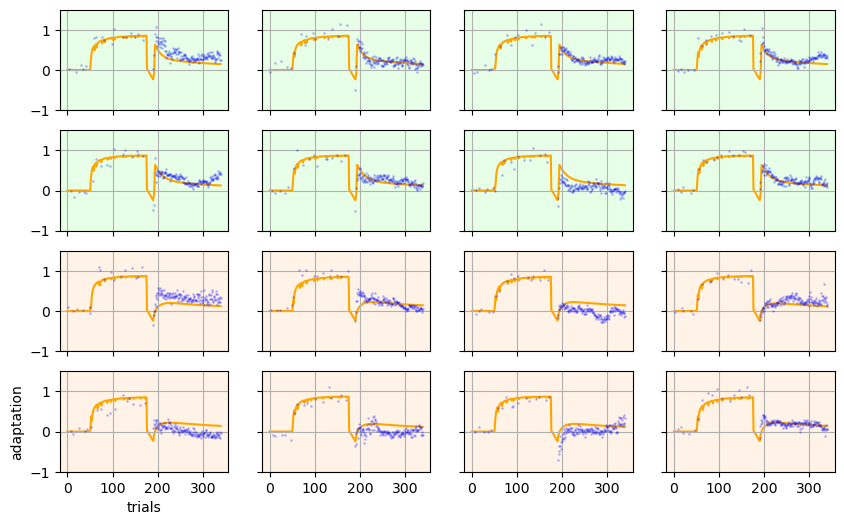

In [90]:
lerner_switch = False


plt.figure(figsize=(10, 6))
plt.subplot(4, 4, 1)
cnt=0
for ii, (this_exp, this_pred) in enumerate(zip(a_exp.T, a_pred.T)):
    this_sub = ii//seeds
    plt.subplot(4, 4, 1 + this_sub)
    polarity = np.sign(np.nanmean(this_exp[:175]))
    if ii % seeds == 0:
        plt.plot(polarity*this_exp,'.', label='Experimental', color='blue', markersize=2, alpha=0.2)
    # if ii == best_seed_idx[this_sub]:
    if ii % seeds == best_seed_idx[0]:
        plt.plot(polarity*this_pred, label='Predicted', color='orange',zorder=0)
        plt.grid() #; print(cnt); cnt+=1
        plt.ylim([-1,1.5])

    if this_sub % 4 > 0:
        plt.gca().set_yticklabels([])
    if this_sub < 12:
        plt.gca().set_xticklabels([])

    if not lerner_switch:
        if this_sub <8:
            # plt.axvspan(0, 340, color='green', alpha=0.01)
            plt.gca().set_facecolor((0.9,1,0.9))
        else:
            # plt.axvspan(0,340, color='orange', alpha=0.1)
            plt.gca().set_facecolor((1,0.95,0.9))
    else:
        if this_sub <15:
            # plt.axvspan(0, 340, color='green', alpha=0.01)
            plt.gca().set_facecolor((0.9,0.9,1))
        else:
            # plt.axvspan(0,340, color='orange', alpha=0.1)
            plt.gca().set_facecolor((0.8,0.7,1))
plt.subplot(4, 4, 13)
plt.xlabel('trials')
plt.ylabel('adaptation')
# plt.title('Experimental vs Predicted Data')
# plt.savefig('/homes/ar2342/one_more_dir/contextual_frogs/figs/ersrFitsM19.pdf', format='pdf', bbox_inches='tight')# 
# plt.savefig('/homes/ar2342/one_more_dir/contextual_frogs/figs/lernerFitsM19.pdf', format='pdf', bbox_inches='tight')

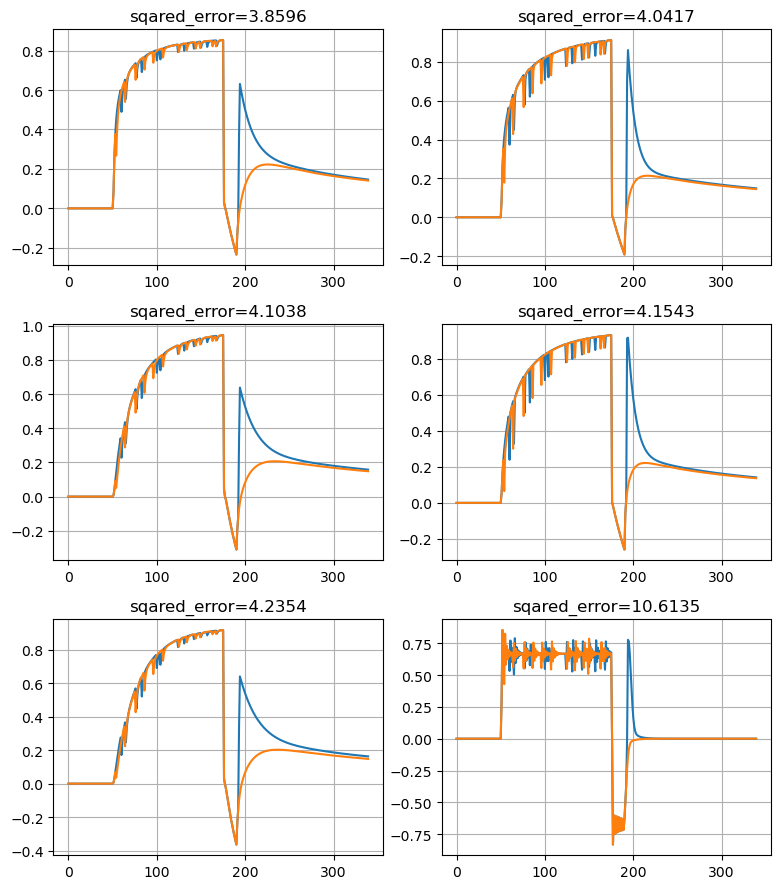

In [91]:
plt.figure(figsize=(8, 9))

prev_pred_ER = np.zeros_like(a_pred[:,0])
prev_pred_SR = np.zeros_like(a_pred[:,64*15]) #64 seeds times 8 participants
skipped = 0
jj = 1
for ii, ss in enumerate(seed_data['seeds_ranked']):
    this_pred_ER = a_pred[:, ss]  
    this_pred_SR = a_pred[:, ss + 64*15] 
    if np.isnan(this_pred_ER).any() or np.isnan(this_pred_SR).any():
        print(f'Found NaN in prediction for seed index {ss}')
    else:
        this_diff_ER = np.abs(this_pred_ER - prev_pred_ER).max()
        this_diff_SR = np.abs(this_pred_SR - prev_pred_SR).max()
        if this_diff_ER > 10e-2 or this_diff_SR > 10e-2:
            plt.subplot(3, 2, jj)

            plt.plot(this_pred_ER)
            plt.plot(this_pred_SR)
            plt.grid()
            # plt.title(f'Seed index {ss}, max diff from previous:\nER={this_diff_ER:.4f}, SR={this_diff_SR:.4f}\n sqared_error={seed_data["se_per_seed"][ss]}\n skipped {skipped} seeds so far')
            plt.title(f'sqared_error={seed_data["se_per_seed"][ss]/16:.4f}')
            skipped = 0
            jj += 1
            if jj > 6:
                break
        else:
            skipped +=1
        prev_pred_ER = this_pred_ER + 0.
        prev_pred_SR = this_pred_SR + 0.
plt.tight_layout()

In [92]:
# np.savetxt('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/dual_rateNL_bics_v1.txt', these_bics)

In [93]:
best_seed_idx_within_batch = np.array([best_seed_idx[0]]*16) # +(np.arange(subjs) * seeds)

#create a new model state dict with only the best seeds (seeds are the leading dimension of each parameter tensor)
best_model_state_dict = {}
for key, value in model_state_dict.items():
        print(key, value.shape)
        if key.endswith('_periodic_base'):
                cropped_key = key[:-len('_periodic_base')]
                cropper_key = cropped_key[1:]
                best_model_state_dict[cropper_key] = value[best_seed_idx_within_batch]
        else:
                best_model_state_dict[key] = value


_log_learning_rate_periodic_base torch.Size([64, 1])
_log_learning_rate_decay_periodic_base torch.Size([64, 1])
_output_scale_periodic_base torch.Size([64])
_sp_weight_decay_periodic_base torch.Size([64, 1])
_sigma_x_periodic_base torch.Size([64])
_x_fast_alpha_periodic_base torch.Size([64])
_sigma_b_periodic_base torch.Size([64])
_input_scale_periodic_base torch.Size([64])
_u_feedback_scale_periodic_base torch.Size([64])
_weight_decay_exp_periodic_base torch.Size([64, 1])
_weight_learning_exp_periodic_base torch.Size([64, 1])
_q_scale_periodic_base torch.Size([64])
_bias_lr_periodic_base torch.Size([64])
_tauqlpf_m1_periodic_base torch.Size([64])
_tauylpf_m1_periodic_base torch.Size([64])
_tauelpf_m1_periodic_base torch.Size([64])
_direct_injection_scale_periodic_base torch.Size([64])
_z_biases torch.Size([1024])
_w_in torch.Size([1024])
_w_inq torch.Size([1024])


In [94]:
from models_part2 import BatchedElboGenerativeModelTopMulti
import yaml
from types import SimpleNamespace
args_path = os.path.join(result_path, 'args.yaml')
with open(args_path, 'r') as f:
    args_dict = yaml.unsafe_load(f) #safe_load(f)
args = SimpleNamespace(**args_dict)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

args.bs = subjs  #set batch size to number of subjects


In [95]:
import pickle

In [96]:
'''
sort the rates for dual rate settinig in a correct order
'''

args.at_y_eq_inf = at_y_eq_inf
if at_y_eq_inf=="skip_slow_timescale_plasticity":
    #ensure that in best_model_state_dict learning rates are sorted from low to high (and weight decays accordingly)
    #'log_learning_rate', 'sp_weight_decay' are the effected parameters
    # lr_order = np.argsort(best_model_state_dict['log_learning_rate'])
    # sorted_lr = best_model_state_dict['log_learning_rate'][:,lr_order]
    # sorted_weight_decay = best_model_state_dict['sp_weight_decay'][:,lr_order]

    sorted_lr, lr_order = torch.sort(best_model_state_dict['log_learning_rate'], dim=1, descending=False)
    sorted_weight_decay = torch.gather(best_model_state_dict['sp_weight_decay'], dim=1, index=lr_order)
    best_model_state_dict['log_learning_rate'] = sorted_lr
    best_model_state_dict['sp_weight_decay'] = sorted_weight_decay

In [97]:
# Compare P+ duration 100 (solid) vs 150 (dashed) for a single subject.
subj_idx = 3  # change this to pick a different subject (0-based index)
probe_values = np.arange(-0.2, 1.2 + 0.05 / 2, 0.025, dtype=np.float32)

ref_paradigm = np.concatenate([
    np.zeros(50, dtype=np.float32),
    np.ones(200, dtype=np.float32),
    np.full(600, np.nan, dtype=np.float32),
])




In [98]:
# savepath  = ('/homes/ar2342/one_more_dir/contextual_frogs/gnu_fig_data/allSubFit/conceptParadigm_v3medianB/')
savepath  = ('/homes/ar2342/one_more_dir/contextual_frogs/gnu_fig_data/allSubFit/deleteme/')

In [99]:
this_input_scale = 1

In [100]:
"""
set parameters for a illustration of fixed point locus decay demonstration
unlike the original parameters, these ones that include a fixed learning rate and appropreately scaled weight decay
so that they enable visualisation of the fixed point locus decay nearly all the way from 1 to 0. 
"""

# best_model_state_dict['log_learning_rate_decay'] = torch.tensor(-1000 * np.ones_like(best_model_state_dict['log_learning_rate_decay']))
# best_model_state_dict['log_learning_rate'] = torch.tensor(-10 * np.ones_like(best_model_state_dict['log_learning_rate']))
# best_model_state_dict['input_scale'] = torch.tensor(np.ones_like(best_model_state_dict['input_scale']))
# best_model_state_dict['sp_weight_decay']= -9*torch.tensor(np.ones_like(best_model_state_dict['sp_weight_decay']))
args.enable_sigma_b_tuning = True



In [101]:
ref_out_records = {}
bb_vec = [0.1,0.15,0.2,0.3]
for ii,bb in enumerate(bb_vec):
    best_model_state_dict['sigma_b'] = bb*torch.tensor(np.ones_like(best_model_state_dict['sigma_b']))
    model = BatchedElboGenerativeModelTopMulti(device=device, args=args, 
                                           **(dict(fudge=args.fudge) if hasattr(args, 'fudge') else {}  )).to(device)
    model.get_biases_and_w_in(args.n, device=device)
    model.load_state_dict(best_model_state_dict, strict=False) #allow missing keys since we may have removed the output scale parameters during migration
    ref_out_records[ii] = eval_paradigm_with_inoutmaps(
        model,
        args,
        ref_paradigm,
        probe_values,
        name='ref',
    )

evaluating ref with 850 steps


evaluating ref with 850 steps
evaluating ref with 850 steps
evaluating ref with 850 steps


Text(0, 0.5, 'adaptation/f.p.l.')

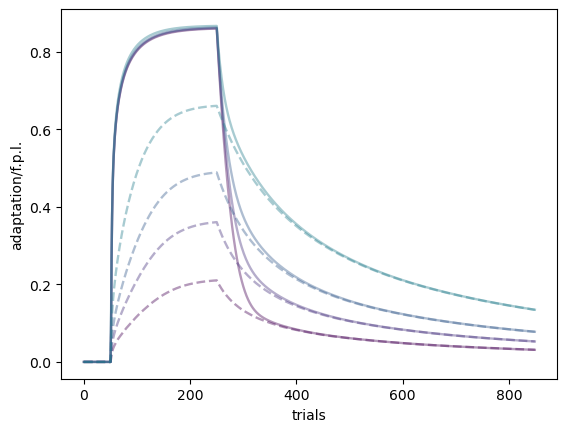

In [102]:
bias_values = [float(bb_vec[ii]) for ii in ref_out_records]
unique_biases = list(dict.fromkeys(bias_values))
# cmap = plt.get_cmap('viridis', len(unique_biases))
cmap = plt.get_cmap('viridis', 2*len(unique_biases))

color_by_bias = {
    bias: cmap(i)
    for i, bias in enumerate(unique_biases)
}

seen_biases = set()

fig, ax = plt.subplots()

for ii, bb in enumerate(bias_values):
    ref_outs = ref_out_records[ii]
    color = color_by_bias[bb]
    if bb not in seen_biases:
        label = f'$\sigma_b={bb:.2f}$'
        seen_biases.add(bb)
    else:
        label = '_nolegend_'
        # ax.plot(
        #     np.log(ref_outs['fixed_points'][:, subj_idx]),
        #     np.log(ref_outs['outputs'][:, subj_idx]),
        #     linestyle='-',
        #     linewidth=1.7,
        #     color=color,
        #     alpha=0.4,
        #     label=label,
        # )

    output_scale_patch = model.softclamp(model.output_scale)[subj_idx].item()
    plt.plot(output_scale_patch*ref_outs['fixed_points'][:, subj_idx], color=color, linestyle='--', linewidth=1.7, alpha=0.4, label=label) 
    plt.plot(ref_outs['outputs'][:, subj_idx], color=color, linestyle='-', linewidth=1.7, alpha=0.4, label='_nolegend_')
    plt.grid()

# np.savetxt(os.path.join(savepath, 'fixed_points.txt'), ref_outs['fixed_points'][:, subj_idx]*this_input_scale)
# np.savetxt(os.path.join(savepath, 'outputs.txt'), ref_outs['outputs'][:, subj_idx])
plt.xlabel('trials')
plt.ylabel('adaptation/f.p.l.')


In [103]:
model.output_scale, model.input_scale

(Parameter containing:
 tensor([2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831,
         2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831],
        device='cuda:0', requires_grad=True),
 tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        device='cuda:0'))

In [104]:
# plt.plot(probe_values,ref_outs['inoutmaps'][200, 0, :]-probe_values)
# plt.xlim([0.9,1.1])
# plt.ylim([-0.04,0.04 ])
# plt.grid()

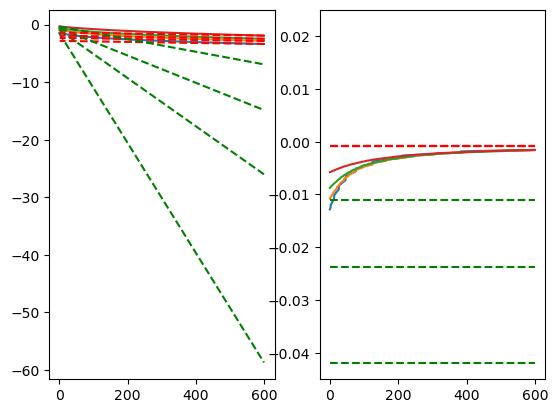

In [105]:
for ii,ref_outs in ref_out_records.items():

    fp = ref_outs['fixed_points'][:,0]
    wd = 1- model.softplus(best_model_state_dict['sp_weight_decay'])[0,0].detach().cpu().numpy()
    # b = best_model_state_dict['sigma_b'][0].detach().cpu().numpy()
    b = bb_vec[ii]
    slope0 = 1/(1+b**2)
    fpd0 = 1-(1-wd) * (1/(1-slope0))
    fp = fp[250:]
    plt.subplot(1,2,1)
    plt.plot(np.log(fp))
    #dashed line starting at fp0 and with slope of log(fpd0)
    plt.plot(np.log(fp[0]) + np.arange(len(fp)) * np.log(fpd0), linestyle='--', color='green', label='initial decay rate')
    #dashed line starting at fp[-1] and with slope of log(wd)
    plt.plot(len(fp)- np.arange(len(fp)), np.log(fp[-1]) - np.arange(len(fp)) * np.log(wd), linestyle='--', color='red', label='weight decay rate')
    plt.subplot(1,2,2)
    plt.plot(np.diff(np.log(fp)))
    plt.ylim([-0.045, 0.025])
    # plt.ylim([-0.001, 0.001])
    #plot weight decay rate for comparison
    plt.plot(np.full_like(fp, np.log(wd)), linestyle='--', color='red', label='weight decay rate')
    plt.plot(np.full_like(fp, np.log(fpd0)), linestyle='--', color='green', label='weight decay rate')


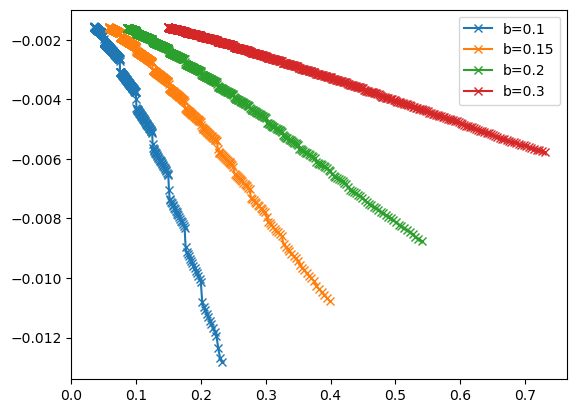

In [106]:
for ii,ref_outs in ref_out_records.items():
    fp = ref_outs['fixed_points'][:,0]
    wd = 1- model.softplus(best_model_state_dict['sp_weight_decay'])[0,0].detach().cpu().numpy()
    # b = best_model_state_dict['sigma_b'][0].detach().cpu().numpy()
    b = bb_vec[ii]
    slope0 = 1/(1+b**2)
    fpd0 = 1-(1-wd) * (1/(1-slope0))
    fp = fp[250:]
    plt.plot(fp[:-1],np.diff(np.log(fp)),'-x')
plt.legend([f'b={b}' for b in bb_vec])

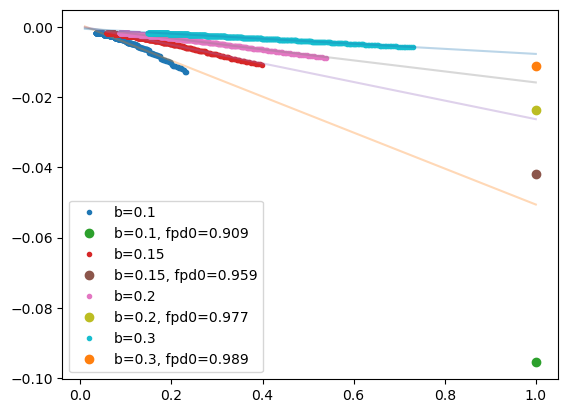

In [107]:
pred,act = [],[]
for ii, ref_outs in ref_out_records.items():
    fp = ref_outs['fixed_points'][250:, 0]
    wd = 1 - model.softplus(best_model_state_dict['sp_weight_decay'])[0, 0].detach().cpu().numpy()
    b = bb_vec[ii]
    slope0 = 1 / (1 + b**2)
    fpd0 = 1 - (1 - wd) / (1 - slope0)

    x, y = fp[:-1], np.diff(np.log(fp))
    plt.plot(x, y, '.', label=f'b={b}')
    m, c = np.polyfit(x, y, 1)
    linspan = [.01, 1]
    plt.plot(linspan, m * np.array(linspan) + c, alpha=.3)
    plt.plot(1, np.log(fpd0), 'o', label=f'b={b}, fpd0={fpd0:.3f}')
    pred.append(np.log(fpd0))
    act.append(m+c)
# plt.xlim(.1, 1)
plt.legend()

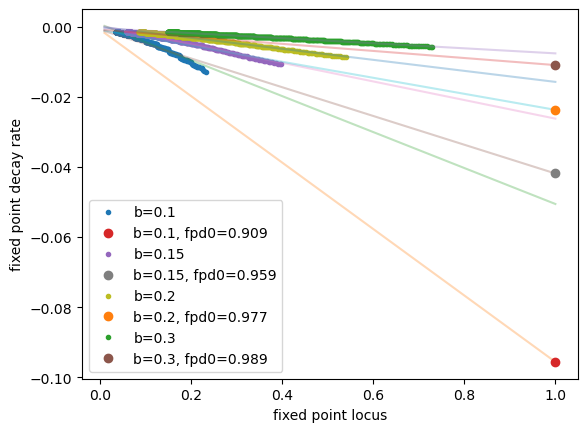

In [108]:
pred,act = [],[]
for ii, ref_outs in ref_out_records.items():
    fp = ref_outs['fixed_points'][250:, 0]
    wd = 1 - model.softplus(best_model_state_dict['sp_weight_decay'])[0, 0].detach().cpu().numpy()
    alpha = 1 - wd
    b = bb_vec[ii]
    slope0 = 1 / (1 + b**2)
    fpd0 = 1 - alpha / (1 - slope0)
    fpd = lambda x: 1 - alpha*(1+slope0/(1-slope0)*x)
    x, y = fp[:-1], np.diff(np.log(fp))
    plt.plot(x, y, '.', label=f'b={b}')
    m, c = np.polyfit(x, y, 1)
    linspan = np.array([.01, 1])
    plt.plot(linspan, np.log(fpd(linspan)), alpha=.3)
    plt.plot(linspan, m * np.array(linspan) + c, alpha=.3)
    plt.plot(1, np.log(fpd0), 'o', label=f'b={b}, fpd0={fpd0:.3f}')
    pred.append(np.log(fpd0))
    act.append(m+c)

    plt.xlabel('fixed point locus')
    plt.ylabel('fixed point decay rate')
# plt.xlim(.1, 1)
plt.legend()

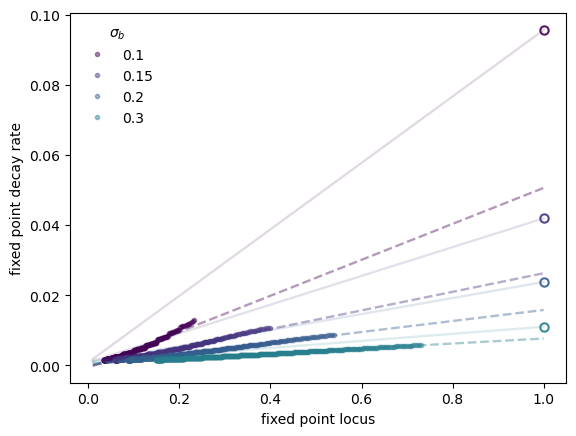

In [109]:
pred, act = [], []

# One consistent color for every bias value
bias_values = [float(bb_vec[ii]) for ii in ref_out_records]
unique_biases = list(dict.fromkeys(bias_values))
# cmap = plt.get_cmap('viridis', len(unique_biases))
cmap = plt.get_cmap('viridis', 2*len(unique_biases))

color_by_bias = {
    bias: cmap(i)
    for i, bias in enumerate(unique_biases)
}

seen_biases = set()

fig, ax = plt.subplots()

for ii, ref_outs in ref_out_records.items():
    fp = ref_outs['fixed_points'][250:, 0]

    wd = (
        1
        - model.softplus(best_model_state_dict['sp_weight_decay'])[0, 0]
        .detach()
        .cpu()
        .numpy()
    )
    alpha = 1 - wd

    b = float(bb_vec[ii])
    color = color_by_bias[b]

    slope0 = 1 / (1 + b**2)
    fpd0 = 1 - alpha / (1 - slope0)

    def fpd(x):
        return 1 - alpha * (1 + slope0 / (1 - slope0) * x)

    x = fp[:-1]
    y = np.diff(np.log(fp))

    m, c = np.polyfit(x, y, 1)
    linspan = np.array([0.01, 1.0])

    # Add each bias to the legend only once
    label = f'{b:g}' if b not in seen_biases else '_nolegend_'
    seen_biases.add(b)

    # Observations
    ax.plot(
        x,
        -y,
        linestyle='none',
        marker='.',
        color=color,
        alpha=0.45,
        label=label,
    )

    # Predicted/theoretical curve
    ax.plot(
        linspan,
        -np.log(fpd(linspan)),
        linestyle='-',
        linewidth=1.7,
        color=color,
        alpha=0.15,
        label='_nolegend_',
    )

    # Linear fit
    ax.plot(
        linspan,
        -(m * linspan + c),
        linestyle='--',
        linewidth=1.7,
        color=color,
        alpha=0.4,
        label='_nolegend_',
    )

    # Predicted value at x=1
    ax.plot(
        1,
        -np.log(fpd0),
        marker='o',
        markersize=6,
        markerfacecolor='none',
        markeredgecolor=color,
        markeredgewidth=1.5,
        linestyle='none',
        alpha=0.9,
        label='_nolegend_',
    )

    pred.append(np.log(fpd0))
    act.append(m + c)

ax.set_xlabel('fixed point locus')
ax.set_ylabel('fixed point decay rate')
ax.legend(title='$\sigma_b$', frameon=False)
plt.show()

In [110]:
np.array(pred) / np.array(act)
# array([1.1783688 , 1.17932775, 1.18117027, 1.17780301])

array([1.89010897, 1.59550989, 1.50510992, 1.43649823])

In [111]:
state_list = [ref_out_records, best_model_state_dict, model.args, bb_vec]
# import pickle
# with open(os.path.join(savepath, 'state_list_VbaselineLR_minus2_wd_minus1sp.pkl'), 'wb') as f:
#     pickle.dump(state_list, f)

In [112]:
bb,ww =model.get_biases_and_w_in(n=1024,device=model.device)

In [113]:
0.12, 1-1/(1+0.25**2)

(0.12, 0.05882352941176472)

In [114]:
np.std(ww.detach().cpu().numpy())

0.9980225

In [115]:
wd, fpd0

(0.9990971273509786, 0.989065209028518)

In [116]:
_, ref_outs_internals = eval_single_wrap(model, ref_paradigm, args, paradigm_name='ref', record_internals=True, single_item=True)

evaluating paradigm ref with 850 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


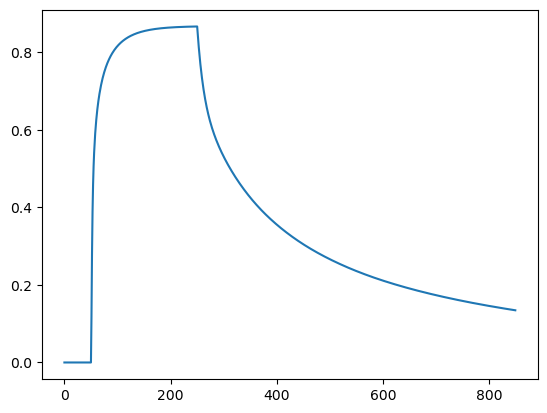

In [117]:
plt.plot(ref_outs['outputs'][:, subj_idx])

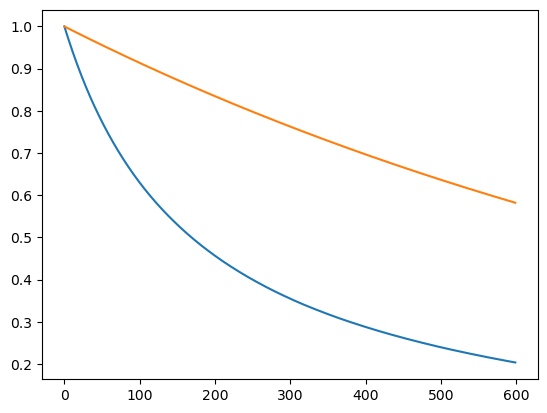

In [118]:
y = ref_outs['fixed_points'][250:, subj_idx]
# plt.semilogy(y/y[0])
fixed_point_decay = y/y[0]
plt.plot(fixed_point_decay)
y = ref_outs_internals['w_out_norm'].squeeze().detach().cpu().numpy()[250:,0]
# plt.semilogy(y/y[0])
w_out_norm_decay = y/y[0]
plt.plot(w_out_norm_decay)

np.savetxt(os.path.join(savepath, 'fixed_point_decay.txt'), fixed_point_decay)
np.savetxt(os.path.join(savepath, 'w_out_norm_decay.txt'), w_out_norm_decay)
full_w_out_trajectory = ref_outs_internals['w_out_norm'].squeeze().detach().cpu().numpy()[:,0]
np.savetxt(os.path.join(savepath, 'full_w_out_trajectory.txt'), full_w_out_trajectory)
np.savetxt(os.path.join(savepath, 'full_w_out_trajectory_normalized.txt'), full_w_out_trajectory/np.abs(full_w_out_trajectory).max())

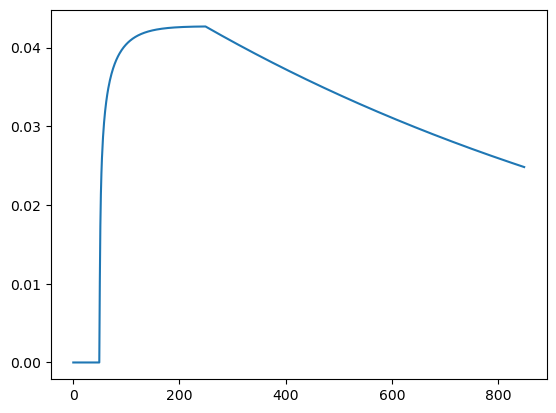

In [119]:
plt.plot(ref_outs_internals['w_out_norm'].squeeze().detach().cpu().numpy()[:,0])